# Heat-Risk Screening — Deliverable 3 (Final Integrated Notebook)

**Course:** Computational Data Analysis with Python (CDAP), TUM
**Track 1 — Heat-risk screening** · Kriti Shrestha & Jonas Juchelka

This notebook is the final, standalone synthesis of the project. It runs top to
bottom from a clean kernel and does not depend on the Deliverable 1 or 2
notebooks. It carries its own data-loading code and reads the shared dataset
from `../archive/`.

We study urban summer heat exposure across six European cities and build a
screening tool that flags the hottest measurement locations. The notebook walks
the full path from the question, through the data and its quality, the analysis
and its validation, to an honest read of uncertainty and a concrete
recommendation a city could act on.

## 0. Setup

We import the scientific Python stack and scikit-learn, fix a single random
seed so every result is reproducible, and set a consistent plotting style.
Nothing here is analysis yet; it just prepares the environment.

In [1]:
from pathlib import Path
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    StratifiedKFold, GroupKFold, cross_val_predict, cross_val_score,
    GridSearchCV, learning_curve,
)
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    precision_score, recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
warnings.filterwarnings('ignore', category=FutureWarning)

print('Libraries loaded.')
print(f'pandas {pd.__version__}, numpy {np.__version__}, sklearn loaded')

Libraries loaded.
pandas 2.3.3, numpy 2.4.4, sklearn loaded


## 1. Question and motivation

`fill after running` — elaborate motivation written in Task 12.

## 2. The data

The dataset is **FAIRUrbTemp**, a curated collection of urban air-temperature
measurements from European cities. Each city has a set of fixed measurement
stations, and each station records hourly **air temperature** (`ta`) in degrees
Celsius. Air temperature is the only measured variable; everything else we use
is station context (where the station is, how high its sensor sits).

The files are stored in **SEF (Station Exchange Format)**: a 12-line header
with station identity and units, then a tab-separated table whose key column is
`Value` (the temperature) alongside `Year, Month, Day, Hour, Minute`. Missing
readings appear either as the literal text `NA` or as the sentinel `-999`; we
fold both into proper missing values so they never pollute a temperature
average. Our **unit of analysis is the station**: every row of the modeling
table we build later is one station.

### 2.1 Load the hourly records

We parse every station file into one long table. Two details matter for
correctness. First, a station's id is the filename stem before `_AirTemp_`,
which keeps compound ids such as `AWEL_Blumenfeld` intact. Second, we normalise
ids to Unicode NFC so that stations with umlauts (for example Basel's
`Münsterplatz`) match the metadata files later; macOS stores the filenames in a
different normalisation (NFD) than the metadata tables (NFC), and without this
step those stations would silently fail to merge.

In [2]:
ARCHIVE = Path('../archive')
HOURLY_DIR = ARCHIVE / 'data' / 'hourly'
META_DIR   = ARCHIVE / 'data' / 'metadata'
CACHE_DIR  = Path('cache'); CACHE_DIR.mkdir(exist_ok=True)
HOURLY_PARQUET = CACHE_DIR / 'hourly_long.parquet'

assert HOURLY_DIR.exists(), f'Dataset not found at {HOURLY_DIR.resolve()}'

def parse_sef_file(path: Path) -> pd.DataFrame:
    """Parse one FAIRUrbTemp SEF TSV into long format (city, station_id, datetime, ta).

    station_id is the filename stem before '_AirTemp_' (handles 'D2195' and
    'AWEL_Blumenfeld'), Unicode-normalized to NFC so umlaut station names match
    the metadata TSVs. '-999' is a missing-value sentinel folded into NA.
    """
    df = pd.read_csv(
        path, sep='\t', skiprows=12, na_values=['NA', '-999', '-999.0'],
        dtype={'Year':'Int64','Month':'Int64','Day':'Int64','Hour':'Int64','Minute':'Int64'},
        low_memory=False,
    )
    parts = df[['Year','Month','Day','Hour','Minute']].rename(columns=str.lower)
    return pd.DataFrame({
        'city': path.parent.name,
        'station_id': unicodedata.normalize('NFC', path.stem.split('_AirTemp_')[0]),
        'datetime': pd.to_datetime(parts),
        'ta': pd.to_numeric(df['Value'], errors='coerce'),
    })

if HOURLY_PARQUET.exists():
    print(f'Loading cached parquet {HOURLY_PARQUET} ...')
    hourly = pd.read_parquet(HOURLY_PARQUET)
else:
    print('Parsing SEF files (first run, ~1-2 min) ...')
    files = [f for c in sorted(HOURLY_DIR.iterdir()) if c.is_dir()
             for f in sorted(c.glob('*.tsv'))]
    hourly = pd.concat([parse_sef_file(f) for f in files], ignore_index=True)
    hourly['city'] = hourly['city'].astype('category')
    hourly['station_id'] = hourly['station_id'].astype('category')
    hourly.to_parquet(HOURLY_PARQUET, index=False)
    print(f'Saved {HOURLY_PARQUET} ({HOURLY_PARQUET.stat().st_size/1e6:.1f} MB)')

print(f'Loaded {len(hourly):,} rows, {hourly.station_id.nunique()} stations, '
      f'{hourly.city.nunique()} cities')

Loading cached parquet cache/hourly_long.parquet ...


Loaded 16,969,491 rows, 712 stations, 9 cities


## 3. From raw records to a modeling table

We now turn millions of hourly readings into one row per station with a heat
measure and the features we will model. Every transformation here is
reproducible and explained, because the quality of this step decides whether
the later model means anything.

### 3.1 Heat measure and the two definitions of "hotspot"

For each station we summarise its summers (June to August, 2019-2022) with the
**95th percentile of hourly air temperature** (`p95`). The 95th percentile
captures how hot a station gets during its hottest hours, while ignoring a
single freak reading that a plain maximum would over-react to. We keep only
stations with at least 50% of the possible summer hours, so a sparse station
cannot produce a noisy percentile.

We then label "hotspots" two different ways, and the contrast between them is
the analytical heart of this project:

- **Absolute hotspot** — the station's `p95` is in the top quartile across *all*
  stations in *all* cities. This is dominated by climate: a warm city's stations
  are hot in absolute terms.
- **Within-city (local) hotspot** — the station's `p95` is in the top quartile
  *inside its own city*. This removes the city's background climate and isolates
  **microclimate**: which spots run hot relative to their neighbours.

A planner needs both. The absolute view says which cities run hottest; the
within-city view says where the local hotspots sit inside a given city.

In [3]:
STUDY_YEARS = [2019, 2020, 2021, 2022]
SUMMER_MONTHS = [6, 7, 8]
MAX_OBS = len(STUDY_YEARS) * 92 * 24    # theoretical max summer hours
MIN_AVAILABILITY = 0.50

m = (hourly['datetime'].dt.year.isin(STUDY_YEARS)
     & hourly['datetime'].dt.month.isin(SUMMER_MONTHS))
summer = hourly.loc[m].dropna(subset=['ta']).copy()

n_obs = summer.groupby('station_id', observed=True).size()
keep = n_obs[n_obs >= MIN_AVAILABILITY * MAX_OBS].index
summer = summer[summer['station_id'].isin(keep)]

risk = (summer.groupby(['city', 'station_id'], observed=True)['ta']
        .quantile(0.95).reset_index(name='p95'))

risk['is_hotspot_absolute'] = (risk['p95'] >= risk['p95'].quantile(0.75)).astype(int)
risk['is_local_hotspot'] = (
    risk.groupby('city', observed=True)['p95']
        .transform(lambda s: (s >= s.quantile(0.75)).astype(int))
)

print(f'Stations after availability filter: {len(risk)} across {risk.city.nunique()} cities')
print(f'Absolute hotspot rate: {risk.is_hotspot_absolute.mean():.0%}')
print(f'Local hotspot rate:    {risk.is_local_hotspot.mean():.0%}')
print('\nAbsolute hotspots by city (expect Zurich-dominated):')
print(risk[risk.is_hotspot_absolute == 1].city.value_counts().to_string())
print('\nLocal hotspots by city (expect spread across cities):')
print(risk[risk.is_local_hotspot == 1].city.value_counts().to_string())

assert 350 <= len(risk) <= 400, f'unexpected station count {len(risk)}'
for col in ['is_hotspot_absolute', 'is_local_hotspot']:
    assert 0.20 <= risk[col].mean() <= 0.30, f'{col} rate off'

Stations after availability filter: 375 across 6 cities
Absolute hotspot rate: 25%
Local hotspot rate:    26%

Absolute hotspots by city (expect Zurich-dominated):
city
Zurich        72
Basel         11
Bern          11
Berlin         1
Amsterdam      0
Biel           0
Birmingham     0
Freiburg       0
NoviSad        0

Local hotspots by city (expect spread across cities):
city
Zurich        46
Basel         25
Bern          14
Birmingham     5
Amsterdam      3
Berlin         3
Biel           0
Freiburg       0
NoviSad        0


### 3.2 Station context features

A station's heat is driven by where it sits. We attach each station's
coordinates and sensor height from the metadata tables (normalising ids to NFC
again so umlaut stations match), then engineer features that describe a
station's position. All of these come only from geography and metadata, never
from the temperature record, so they cannot leak the answer into the model.

In [4]:
station_meta = pd.concat(
    [pd.read_csv(p, sep='\t') for p in sorted(META_DIR.glob('*/station_metadata_*.tsv'))],
    ignore_index=True,
)
station_meta['station_id'] = station_meta['station_id'].map(
    lambda s: unicodedata.normalize('NFC', str(s))
)

def parse_height(v):
    """'4 m' -> 4.0 ; '2-3 m' -> 2.5 ; 2.0 -> 2.0 ; junk -> NaN"""
    if pd.isna(v): return np.nan
    s = str(v).lower().replace('m', '').strip()
    if '-' in s:
        a, b = s.split('-', 1)
        try: return (float(a) + float(b)) / 2
        except ValueError: return np.nan
    try: return float(s)
    except ValueError: return np.nan

station_meta['sensor_height_parsed'] = station_meta['sensor_height_m'].apply(parse_height)

meta_cols = ['station_id', 'latitude', 'longitude', 'sensor_height_parsed']
if 'altitude_m' in station_meta.columns:
    meta_cols.append('altitude_m')
df = risk.merge(station_meta[meta_cols], on='station_id', how='left')
if 'altitude_m' not in df.columns:
    df['altitude_m'] = np.nan

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat = np.radians(lat2 - lat1); dlon = np.radians(lon2 - lon1)
    a = (np.sin(dlat/2)**2
         + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2)
    return 2 * R * np.arcsin(np.sqrt(a))

cent = (df.groupby('city', observed=True)[['latitude', 'longitude']]
          .mean().rename(columns={'latitude': 'clat', 'longitude': 'clon'}))
df = df.merge(cent, on='city')
df['distance_to_centroid'] = haversine_km(df.latitude, df.longitude, df.clat, df.clon)
df['city'] = df['city'].astype(str)

assert df[['latitude', 'longitude']].notna().all().all(), \
    'some stations have no coordinates -> station_id mismatch with metadata'
print(f'All {len(df)} stations matched metadata coordinates.')

All 375 stations matched metadata coordinates.


**New spatial features (Deliverable 3).** Distance to the city centre is a coarse
position signal. We add three richer ones, all derived from the coordinates we
already hold:

- **Local station density** counts how many other stations lie within 1 km. A
  dense cluster of sensors usually marks a built-up core, a proxy for the kind of
  place that traps heat.
- **Neighbourhood heat (kNN p95)** is the average `p95` of the five nearest
  *other* stations. It asks whether a station sits in a hot pocket. Because this
  feature is built from temperatures, using it carelessly would leak the answer,
  so when we validate we recompute it inside each training fold (Section 6). The
  column built here is for exploration and the full-data view only.
- **Direction from the centre** (the compass bearing, split into its sine and
  cosine) lets the model learn that, say, the south side of a city runs hotter,
  which plain distance cannot express.

We also keep **elevation** where the metadata provides it; it is populated for
only a few cities, so it acts as a city-specific signal rather than a universal
one.

In [5]:
coords = df[['latitude', 'longitude']].to_numpy()
n = len(df)

# pairwise great-circle distances (n is small, ~375, so a dense matrix is fine)
dist_km = np.zeros((n, n))
for i in range(n):
    dist_km[i] = haversine_km(coords[i, 0], coords[i, 1], coords[:, 0], coords[:, 1])

# Local station density: other stations within 1 km (exclude self on the diagonal)
within_1km = (dist_km <= 1.0)
np.fill_diagonal(within_1km, False)
df['station_density_1km'] = within_1km.sum(axis=1)

# kNN-neighbour p95 (k=5 nearest OTHER stations), full-data version for EDA only
K = 5
p95_vals = df['p95'].to_numpy()
knn_p95 = np.empty(n)
for i in range(n):
    order = np.argsort(dist_km[i])
    order = order[order != i][:K]
    knn_p95[i] = p95_vals[order].mean()
df['knn_p95_k5'] = knn_p95

# Direction from the city centroid, as sine/cosine of the bearing
dlon = np.radians(df['longitude'] - df['clon'])
lat1 = np.radians(df['clat']); lat2 = np.radians(df['latitude'])
x = np.sin(dlon) * np.cos(lat2)
y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
bearing = np.arctan2(x, y)
df['bearing_sin'] = np.sin(bearing)
df['bearing_cos'] = np.cos(bearing)

NUM_FEATURES_BASE = ['latitude', 'longitude', 'distance_to_centroid', 'sensor_height_parsed']
NUM_FEATURES_SPATIAL = ['station_density_1km', 'bearing_sin', 'bearing_cos', 'altitude_m']
NUM_FEATURES = NUM_FEATURES_BASE + NUM_FEATURES_SPATIAL
CAT_FEATURES = ['city']
FEATURES = NUM_FEATURES + CAT_FEATURES

print('New spatial features built. Summary:')
print(df[['station_density_1km', 'knn_p95_k5', 'bearing_sin', 'bearing_cos']].describe().round(2))
print('\naltitude_m non-missing by city:')
print(df.groupby('city')['altitude_m'].apply(lambda s: s.notna().sum()).to_string())
assert df['station_density_1km'].min() >= 0
assert df[['bearing_sin', 'bearing_cos']].abs().max().max() <= 1.0 + 1e-9

New spatial features built. Summary:
       station_density_1km  knn_p95_k5  bearing_sin  bearing_cos
count               375.00      375.00       375.00       375.00
mean                  5.59       29.44        -0.05         0.00
std                   4.02        1.47         0.68         0.73
min                   0.00       23.73        -1.00        -1.00
25%                   2.00       29.21        -0.73        -0.76
50%                   5.00       29.69        -0.04         0.04
75%                   8.00       30.14         0.62         0.75
max                  17.00       31.95         1.00         1.00

altitude_m non-missing by city:
city
Amsterdam       0
Basel           0
Berlin         10
Bern            0
Birmingham      0
Zurich        184


### 3.3 A leak-free preprocessing pipeline

Everything the model learns from the data must be learned on the training rows
only, never the rows we test on. We wrap preprocessing in a scikit-learn
`Pipeline` so that during cross-validation each step is fit on the training fold
and merely applied to the held-out fold. The numeric features are median-imputed
(the parsed sensor height and elevation have gaps) and standardised; the city is
left out of the model as a predictor because the within-city target already has
the city removed, and feeding the city back in would be circular. We keep `city`
only as a grouping key for the cross-city test in Section 6.

The neighbourhood-heat feature needs special care: its value for a station
depends on other stations' temperatures, so if a test station's neighbours
include training stations we must compute it using training neighbours only. We
implement it as a transformer that stores the training coordinates and p95 when
it is fit, and computes neighbour averages for any rows it later transforms.

In [6]:
from sklearn.base import BaseEstimator, TransformerMixin

class KNNNeighbourP95(BaseEstimator, TransformerMixin):
    """Append mean p95 of the k nearest TRAINING stations (leak-free).

    Expects input columns ['latitude','longitude','p95']; outputs one column.
    On fit it memorises training coords+p95; on transform it looks up neighbours
    among the training stations only."""
    def __init__(self, k=5):
        self.k = k
    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.train_lat_, self.train_lon_, self.train_p95_ = A[:, 0], A[:, 1], A[:, 2]
        return self
    def transform(self, X):
        A = np.asarray(X, dtype=float)
        out = np.empty(len(A))
        for i in range(len(A)):
            d = haversine_km(A[i, 0], A[i, 1], self.train_lat_, self.train_lon_)
            order = np.argsort(d)
            # drop exact-self matches (distance 0) so a train row uses its neighbours
            order = order[d[order] > 1e-9][:self.k]
            out[i] = self.train_p95_[order].mean()
        return out.reshape(-1, 1)

def make_pipeline(classifier, add_knn=False):
    """Leak-free ColumnTransformer (+ optional kNN p95) + classifier."""
    transformers = [
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), NUM_FEATURES),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
    ]
    if add_knn:
        transformers.append(('knn', Pipeline([
            ('nbr', KNNNeighbourP95(k=5)),
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), ['latitude', 'longitude', 'p95']))
    pre = ColumnTransformer(transformers)
    return Pipeline([('pre', pre), ('clf', classifier)])

# Feature matrices. X carries p95 ONLY so the kNN transformer can read it; the
# raw p95 column is never exposed to the numeric block (NUM_FEATURES excludes it).
X = df[FEATURES + ['p95']].copy()
y_abs = df['is_hotspot_absolute'].copy()
y_loc = df['is_local_hotspot'].copy()
groups = df['city'].to_numpy()

# smoke test (not evaluation)
_smoke = make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), add_knn=True)
_smoke.fit(X, y_abs)
assert _smoke.predict_proba(X).shape == (len(X), 2)
print('Pipeline smoke test OK (with leak-free kNN p95 feature).')

Pipeline smoke test OK (with leak-free kNN p95 feature).


## 4. Exploratory data analysis

Before modeling we look at the data to understand the patterns the model will
have to capture, and to motivate the two-target design. Two findings stand out
and shape the rest of the notebook.

### 4.1 Climate dominates the absolute ranking

If we rank stations by raw `p95`, the hottest are concentrated in the warmest
cities. The boxplot below shows each city's spread of station `p95` values. The
cities sit at clearly different levels, so an absolute "top quartile" label is
mostly a statement about which city a station is in.

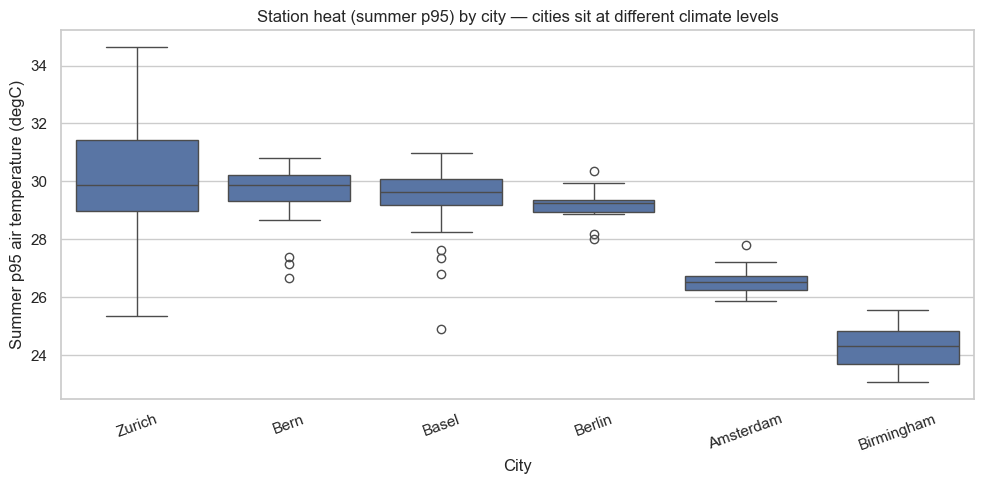

In [7]:
order = df.groupby('city')['p95'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='city', y='p95', order=order, ax=ax)
ax.set_xlabel('City'); ax.set_ylabel('Summer p95 air temperature (degC)')
ax.set_title('Station heat (summer p95) by city — cities sit at different climate levels')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

### 4.2 Microclimate exists within every city

Within a single city, stations still differ by several degrees. That within-city
spread is the microclimate signal our local-hotspot target tries to predict. The
plot below shows, for each city, how far its hottest stations sit above its
coolest, confirming there is a real within-city range to explain.

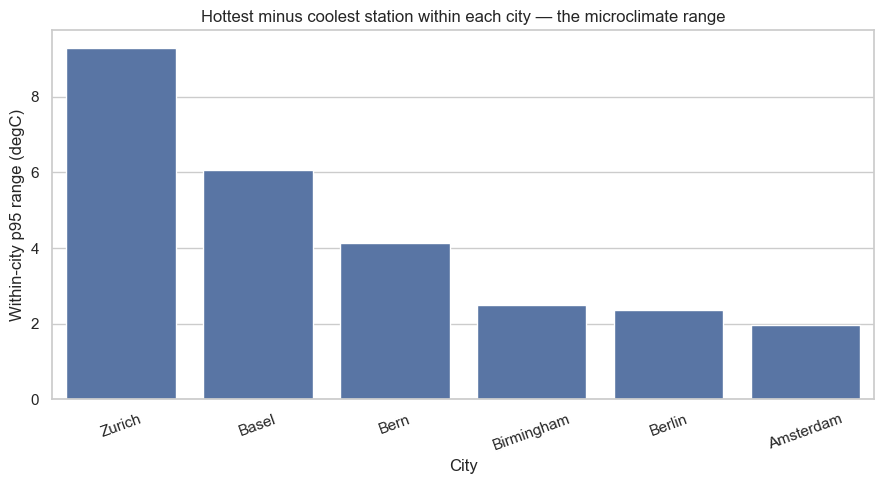

              min    max  range
city                           
Zurich      25.34  34.63   9.29
Basel       24.92  31.00   6.08
Bern        26.67  30.80   4.13
Birmingham  23.06  25.57   2.50
Berlin      28.00  30.36   2.36
Amsterdam   25.87  27.82   1.95


In [8]:
spread = (df.groupby('city')['p95'].agg(['min', 'max'])
            .assign(range=lambda d: d['max'] - d['min'])
            .sort_values('range', ascending=False))
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=spread.index, y=spread['range'], ax=ax)
ax.set_xlabel('City'); ax.set_ylabel('Within-city p95 range (degC)')
ax.set_title('Hottest minus coolest station within each city — the microclimate range')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print(spread.round(2).to_string())

### 4.3 Do the new spatial features track heat?

A quick check that the engineered features carry signal worth modeling. We plot
neighbourhood heat (mean p95 of the five nearest stations) against a station's
own p95; a positive trend means heat is spatially clustered, which is what the
feature is meant to capture.

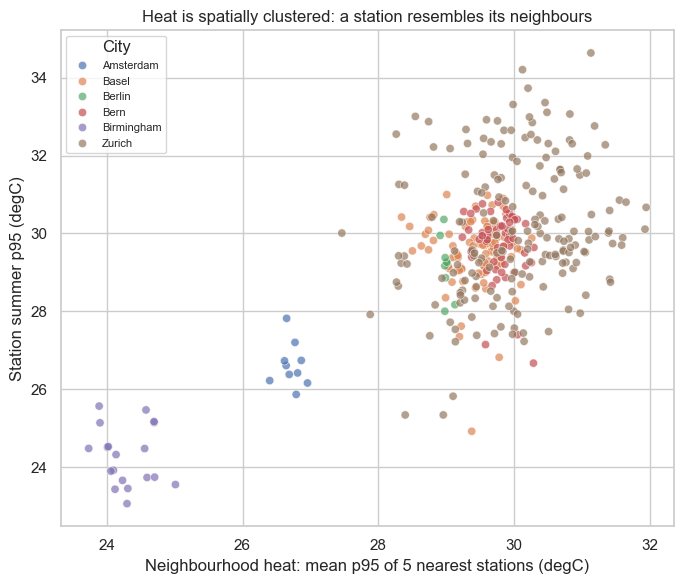

Correlation(neighbour p95, own p95) = 0.68


In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=df, x='knn_p95_k5', y='p95', hue='city', ax=ax, alpha=0.7)
ax.set_xlabel('Neighbourhood heat: mean p95 of 5 nearest stations (degC)')
ax.set_ylabel('Station summer p95 (degC)')
ax.set_title('Heat is spatially clustered: a station resembles its neighbours')
ax.legend(title='City', fontsize=8, loc='best')
plt.tight_layout(); plt.show()
corr = df['knn_p95_k5'].corr(df['p95'])
print(f'Correlation(neighbour p95, own p95) = {corr:.2f}')